In [4]:
import pandas as pd
from Bio.SeqUtils.ProtParam import ProteinAnalysis

df = pd.read_csv("LCC_variant_sequences.csv")
print("LCC variants:", len(df))
print("Unique names:", df["variant_name"].nunique())
print("Unique sequences:", df["sequence"].nunique())

LCC variants: 189
Unique names: 189
Unique sequences: 189


Computed: 189

Length distribution:
length
258    189
Name: count, dtype: int64

Feature statistics:
       aliphatic_index       gravy          pI  instability_index  pct_charged
count       189.000000  189.000000  189.000000         189.000000   189.000000
mean         78.581067   -0.142654    9.230815          36.810791    13.412083
std           0.779886    0.020404    0.128743           1.066930     0.313815
min          77.170543   -0.216667    8.926953          33.651977    12.790698
25%          78.294574   -0.154264    9.114492          36.382597    13.178295
50%          78.682171   -0.141085    9.273020          36.804690    13.565891
75%          78.682171   -0.126744    9.297260          37.458178    13.565891
max          80.193798   -0.105039    9.689485          39.492287    15.891473


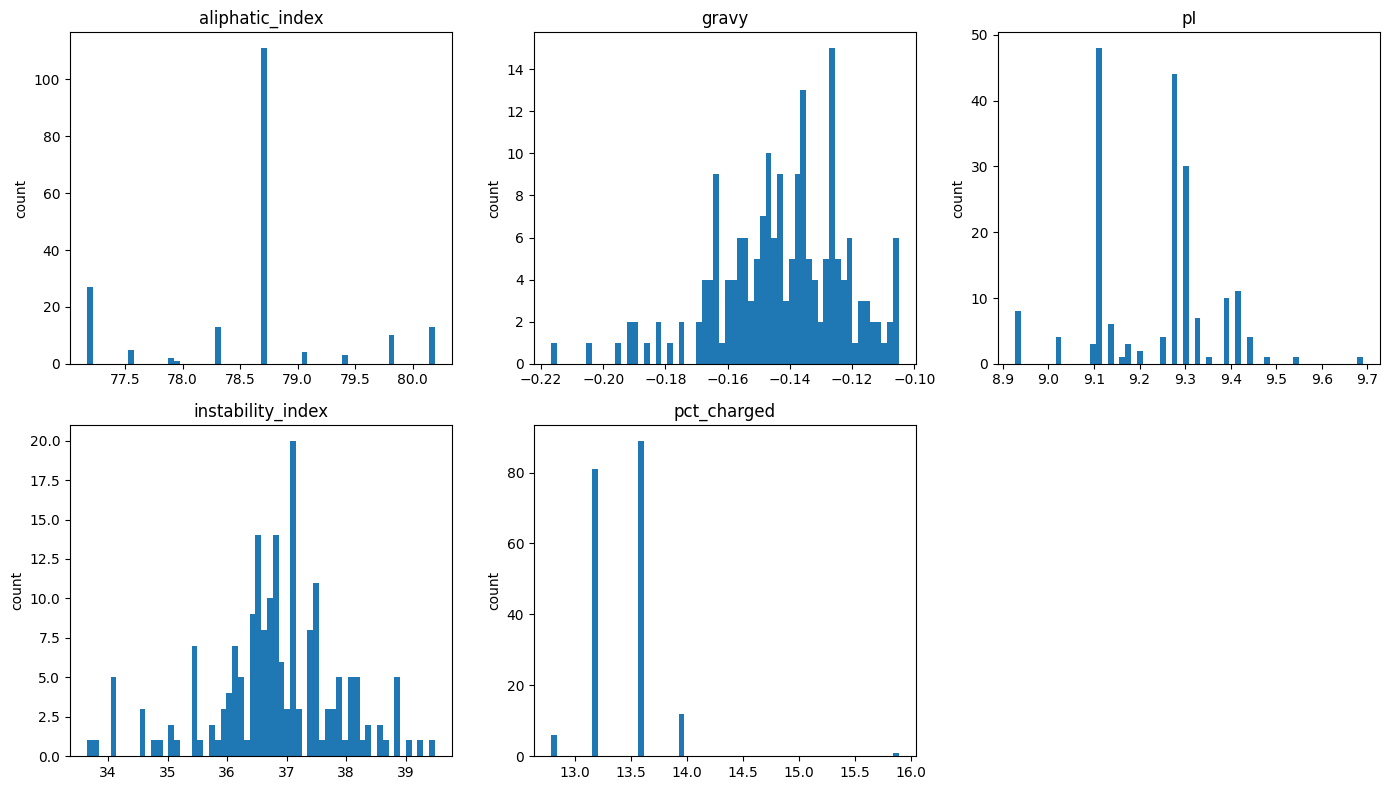

In [7]:
def aliphatic_index(aa):
    return aa.get("A",0) + 2.9*aa.get("V",0) + 3.9*(aa.get("I",0)+aa.get("L",0))

rows = []
for _, r in df.iterrows():
    name = r["variant_name"]
    seq = str(r["sequence"]).strip().upper()
    if not seq or (set(seq) - set("ACDEFGHIKLMNPQRSTVWY")):
        print("skip", name)
        continue
    pa = ProteinAnalysis(seq)
    aa = pa.amino_acids_percent
    rows.append({
        "variant_name": name,
        "length": len(seq),
        "aliphatic_index": aliphatic_index(aa),
        "gravy": pa.gravy(),
        "pI": pa.isoelectric_point(),
        "instability_index": pa.instability_index(),
        "pct_charged": sum(aa.get(x,0) for x in ["D","E","K","R"]),
    })

df_feat = pd.DataFrame(rows)
print("Computed:", len(df_feat))
print()
print("Length distribution:")
print(df_feat["length"].value_counts())
print()
print("Feature statistics:")
print(df_feat[["aliphatic_index","gravy","pI","instability_index","pct_charged"]].describe())

# ---- histograms ----
import matplotlib.pyplot as plt

features = ["aliphatic_index", "gravy", "pI", "instability_index", "pct_charged"]
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, f in zip(axes.flat, features):
    ax.hist(df_feat[f], bins=60)
    ax.set_title(f)
    ax.set_ylabel("count")
axes.flat[5].axis("off")   # no 6th feature
plt.tight_layout()
plt.show()

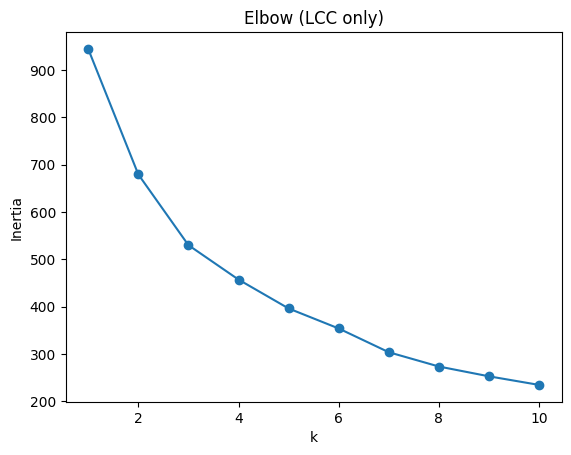

In [6]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

features = ["aliphatic_index","gravy","pI","instability_index","pct_charged"]
X = StandardScaler().fit_transform(df_feat[features].values)

inertias = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X)
    inertias.append(km.inertia_)

plt.plot(range(1,11), inertias, "o-")
plt.xlabel("k"); plt.ylabel("Inertia"); plt.title("Elbow (LCC only)")
plt.show()